# 🧩 Trabajo Práctico Integrador · Entrega 6: Evaluación del Modelo de Clasificación

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Unidad N° 6 · Evaluación de Modelos y Cierre del TPI)
* **Comisión:** 8
* **Integrantes del Equipo:**
  * **López, Emanuel Gustavo** (Legajo: 101135)
  * **Del Corro, Santino**
* **Número de Entrega:** Entrega N° 6 (Notebook independiente, ejecutable y reproducible)
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H — 25.000 reservas)
* **Variable Objetivo:** `is_canceled` (`1` = Reserva Cancelada [Caso Positivo], `0` = Reserva No Cancelada [Caso Negativo])
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `scikit-learn`, `matplotlib`, `seaborn`)**

---

## 1. Identificación y Propósito de la Entrega

En la Entrega 5 construimos un primer modelo de clasificación supervisada basado en un **Árbol de Decisión (`DecisionTreeClassifier`)** para anticipar la cancelación de reservas hoteleras utilizando como variable objetivo `is_canceled`.

El **propósito de esta Entrega 6** es avanzar desde la generación de predicciones hacia la **evaluación crítica y rigurosa del desempeño del modelo** sobre observaciones no utilizadas durante su aprendizaje (conjunto de prueba). Específicamente, este notebook busca:
1. Reproducir de forma íntegra y autónoma el pipeline de preparación en **SQL** y entrenamiento del árbol de decisión en **Python**.
2. Analizar la **capacidad de generalización** mediante la separación entre entrenamiento y prueba, verificando si existen señales de sobreajuste (*overfitting*).
3. Construir e interpretar la **Matriz de Confusión** identificando Verdaderos Positivos (`TP`), Verdaderos Negativos (`TN`), Falsos Positivos (`FP`) y Falsos Negativos (`FN`), considerando como **caso positivo (`1`) la cancelación de la reserva**.
4. Calcular e interpretar en contexto las cuatro métricas solicitadas: **`Accuracy`**, **`Precision`**, **`Recall`** y **`F1-score`**.
5. Examinar el significado operativo y económico de los **Falsos Positivos** y **Falsos Negativos** en la gestión hotelera, justificando cuál resulta más relevante según la decisión de negocio, y formular una conclusión fundamentada sobre la utilidad y las limitaciones del modelo.

---
## 2. Preparación del Entorno y Reproducción del Modelo (Continuidad con la Entrega 5)

Para que este notebook sea **100% independiente y ejecutable desde el comienzo** sin necesitar abrir la Entrega 5 ni subir archivos manualmente en Google Colab:
1. Se verifican e instalan automáticamente las librerías requeridas (`duckdb`, `pandas`, `scikit-learn`, `matplotlib`, `seaborn`).
2. Se carga el dataset original `hotel booking TPI grupo H.csv` (descargándolo automáticamente desde el repositorio GitHub del equipo si no se encuentra en el directorio local de Colab).
3. Se utiliza **SQL (DuckDB)** para recuperar la variable objetivo `is_canceled` y reconstruir los mismos predictores seleccionados en las Entregas 4 y 5:
   * **Variables cuantitativas y derivadas:** `lead_time`, `total_stays_nights` (`stays_in_weekend_nights + stays_in_week_nights`), `total_guests` (`adults + COALESCE(children, 0) + babies`), `previous_cancellations`, `booking_changes`, `adr`, `required_car_parking_spaces`, `total_of_special_requests`.
   * **Variables categóricas:** `hotel`, `market_segment`, `deposit_type` y `customer_type`.

In [1]:
# 1. Preparación automática del entorno y librerías (SQL + Python)
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

for package in ["duckdb", "pandas", "scikit-learn", "matplotlib", "seaborn"]:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# 2. Carga reproducible del dataset original (Local o descarga automática desde GitHub en Colab)
GITHUB_RAW_URL = "https://raw.githubusercontent.com/Emanstor/tpi-iad-comision8/main/hotel%20booking%20TPI%20grupo%20H.csv"
POSSIBLE_PATHS = [
    Path("hotel booking TPI grupo H.csv"),
    Path("sample_data/hotel booking TPI grupo H.csv"),
    Path("hotel booking TPI grupo H (3).csv")
]

data_path = next((p for p in POSSIBLE_PATHS if p.exists()), None)
if data_path is None:
    data_path = Path("hotel booking TPI grupo H.csv")
    print("Descargando dataset original desde el repositorio GitHub del equipo...")
    urlretrieve(GITHUB_RAW_URL, data_path)

reservas_raw = pd.read_csv(data_path)

# 3. Conexión a DuckDB y registro de la tabla 'reservas'
con = duckdb.connect(":memory:")
con.register("reservas_raw", reservas_raw)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_raw")

print(f"✅ Dataset cargado en DuckDB: {len(reservas_raw):,} observaciones disponibles.")

✅ Dataset cargado en DuckDB: 25,000 observaciones disponibles.


In [2]:
# Recuperación mediante SQL de la variable objetivo (is_canceled) y los predictores de la Entrega 5
df_modelo = con.sql("""
SELECT
    is_canceled,
    lead_time,
    stays_in_weekend_nights + stays_in_week_nights AS total_stays_nights,
    adults + COALESCE(children, 0) + babies AS total_guests,
    previous_cancellations,
    booking_changes,
    adr,
    required_car_parking_spaces,
    total_of_special_requests,
    hotel,
    market_segment,
    deposit_type,
    customer_type
FROM reservas
""").df()

print(f"Variables recuperadas con SQL: {df_modelo.shape[0]:,} filas × {df_modelo.shape[1]} columnas.")
df_modelo.head()

Variables recuperadas con SQL: 25,000 filas × 13 columnas.


,is_canceled,lead_time,total_stays_nights,total_guests,previous_cancellations,booking_changes,adr,required_car_parking_spaces,total_of_special_requests,hotel,market_segment,deposit_type,customer_type
0,1,85,14,3.0,1,0,217.14,0,2,Resort Hotel,Direct,No Deposit,Group
1,1,77,2,2.0,0,1,79.20,0,2,City Hotel,Online TA,No Deposit,Transient
2,0,91,6,1.0,0,1,132.60,0,1,City Hotel,Online TA,No Deposit,Transient
3,0,0,1,2.0,0,0,75.00,0,2,Resort Hotel,Online TA,No Deposit,Transient
4,0,133,5,2.0,0,0,70.04,0,2,City Hotel,Online TA,No Deposit,Transient


---
## 3. Separación entre Entrenamiento y Prueba y Reproducción del Árbol de Decisión

### ¿Por qué es fundamental evaluar el modelo sobre observaciones que no utilizó para aprender?
* Cuando un modelo se ajusta sobre un conjunto de datos, aprende patrones presentes en esas observaciones particulares. Si midiéramos su calidad únicamente sobre esos mismos datos de entrenamiento, obtendríamos una visión excesivamente optimista, ya que no sabríamos si el modelo realmente capturó relaciones generales del fenómeno o si simplemente "memorizó" los casos conocidos.
* Separar los datos en un **conjunto de entrenamiento (`70% = 17.500 reservas`)** y un **conjunto de prueba (`30% = 7.500 reservas`)** permite obtener una primera aproximación genuina a su **capacidad de generalización** frente a reservas futuras.
* Asimismo, contrastar el rendimiento en entrenamiento frente al de prueba permite detectar señales de **sobreajuste (*overfitting*)**: si el modelo funcionara muy bien en entrenamiento pero su desempeño cayera drásticamente en prueba, estaríamos ante un modelo sobreajustado.

In [3]:
# 1. Definición de la variable objetivo (y) y la matriz de predictores (X)
y = df_modelo["is_canceled"]
X = df_modelo.drop(columns="is_canceled")

# 2. Separación estratificada en Entrenamiento (70%) y Prueba (30%)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Codificación de variables categóricas (One-Hot Encoding) alineada con el conjunto de entrenamiento
columnas_categoricas = ["hotel", "market_segment", "deposit_type", "customer_type"]
X_train = pd.get_dummies(X_train_raw, columns=columnas_categoricas, drop_first=True)
X_test = pd.get_dummies(X_test_raw, columns=columnas_categoricas, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 4. Entrenamiento del Árbol de Decisión reproducido de la Entrega 5
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

# 5. Predicciones sobre entrenamiento (para chequear sobreajuste) y sobre prueba (para evaluación formal)
y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)
y_prob_test = modelo.predict_proba(X_test)[:, 1]

acc_train = accuracy_score(y_train, y_pred_train)
acc_test = accuracy_score(y_test, y_pred_test)

print(f"📌 Observaciones de entrenamiento: {len(X_train):,} (Canceladas: {y_train.sum():,} | {y_train.mean()*100:.2f}%)")
print(f"📌 Observaciones de prueba:        {len(X_test):,}  (Canceladas: {y_test.sum():,}  | {y_test.mean()*100:.2f}%)")
print("-" * 65)
print(f"🔍 Exactitud (Accuracy) en Entrenamiento: {acc_train:.4f} ({acc_train*100:.2f}%)")
print(f"🔍 Exactitud (Accuracy) en Prueba:        {acc_test:.4f} ({acc_test*100:.2f}%)")

📌 Observaciones de entrenamiento: 17,500 (Canceladas: 6,483 | 37.05%)
📌 Observaciones de prueba:        7,500  (Canceladas: 2,778  | 37.04%)
-----------------------------------------------------------------
🔍 Exactitud (Accuracy) en Entrenamiento: 0.7650 (76.50%)
🔍 Exactitud (Accuracy) en Prueba:        0.7716 (77.16%)


**Verificación de generalización (Entrenamiento vs. Prueba):**
* El modelo alcanza una exactitud del **76,50%** en el conjunto de entrenamiento (`17.500` casos) y del **77,16%** en el conjunto de prueba (`7.500` casos nuevos).
* El hecho de que el desempeño en prueba sea sumamente estable (e incluso levemente superior por décimas al de entrenamiento) confirma que el árbol de decisión con `max_depth=3` **no presenta sobreajuste (*overfitting*)** y conserva su comportamiento al enfrentarse a reservas no vistas durante el entrenamiento.

---

## 4. Construcción e Interpretación de la Matriz de Confusión (Conjunto de Prueba)

Considerando como **caso positivo (`1`) la cancelación de una reserva** (`is_canceled = 1`) y como **caso negativo (`0`) la no cancelación** (`is_canceled = 0`), organizamos los resultados de las **7.500 reservas del conjunto de prueba** tanto mediante **SQL** como en **Python**:

* **Verdadero Positivo (`TP` - *True Positive*):** El modelo predijo que la reserva se cancelaría (`1`) y **efectivamente se canceló (`1`)**.
* **Verdadero Negativo (`TN` - *True Negative*):** El modelo predijo que la reserva no se cancelaría (`0`) y **efectivamente no se canceló (`0`)**.
* **Falso Positivo (`FP` - *False Positive*):** El modelo predijo cancelación (`1`), pero **la reserva NO se canceló (`0`)** *(Falsa alarma de cancelación)*.
* **Falso Negativo (`FN` - *False Negative*):** El modelo predijo que no se cancelaría (`0`), pero **finalmente la reserva SÍ se canceló (`1`)** *(Cancelación no detectada)*.

In [4]:
# Registro de las predicciones del conjunto de prueba en DuckDB para construir la matriz mediante SQL
evaluacion_df = X_test_raw.copy()
evaluacion_df["is_canceled"] = y_test.to_numpy()
evaluacion_df["predicted_canceled"] = y_pred_test
evaluacion_df["prob_cancelacion"] = y_prob_test.round(4)

con.register("evaluacion_modelo", evaluacion_df)

# Consulta SQL: Conteo de las 4 combinaciones entre valor real y predicción en el conjunto de prueba
resumen_sql_matriz = con.sql("""
SELECT
    is_canceled AS valor_real,
    predicted_canceled AS valor_predicho,
    CASE
        WHEN is_canceled = 1 AND predicted_canceled = 1 THEN 'Verdadero Positivo (TP) — Cancelación bien detectada'
        WHEN is_canceled = 0 AND predicted_canceled = 0 THEN 'Verdadero Negativo (TN) — Estadía firme bien clasificada'
        WHEN is_canceled = 0 AND predicted_canceled = 1 THEN 'Falso Positivo (FP) — Falsa alarma de cancelación'
        WHEN is_canceled = 1 AND predicted_canceled = 0 THEN 'Falso Negativo (FN) — Cancelación no detectada'
    END AS tipo_resultado,
    COUNT(*) AS cantidad_reservas,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS porcentaje_sobre_total_test
FROM evaluacion_modelo
GROUP BY is_canceled, predicted_canceled
ORDER BY is_canceled, predicted_canceled
""").df()

resumen_sql_matriz

,valor_real,valor_predicho,tipo_resultado,cantidad_reservas,porcentaje_sobre_total_test
0,0,0,Verdadero Negativo (TN) — Estadía firme bien clasificada,4710,62.80
1,0,1,Falso Positivo (FP) — Falsa alarma de cancelación,12,0.16
2,1,0,Falso Negativo (FN) — Cancelación no detectada,1701,22.68
3,1,1,Verdadero Positivo (TP) — Cancelación bien detectada,1077,14.36


In [5]:
# Construcción de la Matriz de Confusión en formato matricial y visualización con Python
cm = confusion_matrix(y_test, y_pred_test)
tn, fp, fn, tp = cm.ravel()

matriz_df = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real: No Cancela (0)", "Real: Cancela (1)"],
    columns=["Predice: No Cancela (0)", "Predice: Cancela (1)"]
)

print("📋 Resumen explícito de los 4 cuadrantes (Conjunto de Prueba = 7.500 reservas):")
print(f"  • Verdaderos Negativos (TN): {tn:,} reservas ({tn/len(y_test)*100:.2f}%)")
print(f"  • Falsos Positivos     (FP): {fp:,} reservas   ({fp/len(y_test)*100:.2f}%)")
print(f"  • Falsos Negativos     (FN): {fn:,} reservas ({fn/len(y_test)*100:.2f}%)")
print(f"  • Verdaderos Positivos (TP): {tp:,} reservas ({tp/len(y_test)*100:.2f}%)")

matriz_df

📋 Resumen explícito de los 4 cuadrantes (Conjunto de Prueba = 7.500 reservas):
  • Verdaderos Negativos (TN): 4,710 reservas (62.80%)
  • Falsos Positivos     (FP): 12 reservas   (0.16%)
  • Falsos Negativos     (FN): 1,701 reservas (22.68%)
  • Verdaderos Positivos (TP): 1,077 reservas (14.36%)


,Predice: No Cancela (0),Predice: Cancela (1)
Real: No Cancela (0),4710,12
Real: Cancela (1),1701,1077


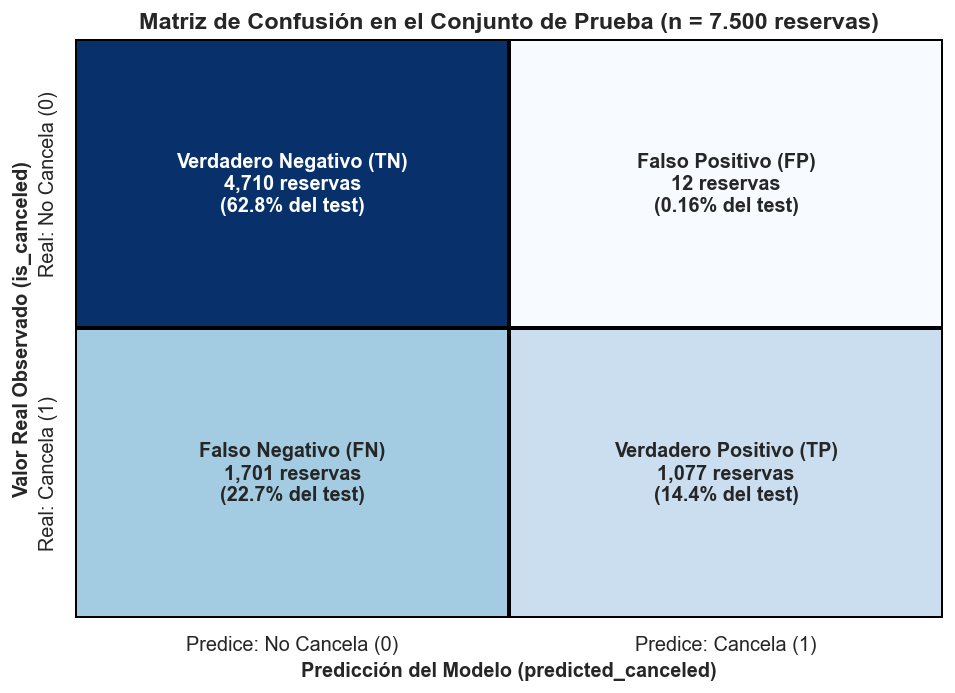

In [6]:
# Visualización gráfica de la Matriz de Confusión con etiquetas claras de TN, FP, FN y TP
fig, ax = plt.subplots(figsize=(7.5, 5.5))

etiquetas_celdas = np.array([
    [f"Verdadero Negativo (TN)\n{tn:,} reservas\n({tn/len(y_test)*100:.1f}% del test)",
     f"Falso Positivo (FP)\n{fp:,} reservas\n({fp/len(y_test)*100:.2f}% del test)"],
    [f"Falso Negativo (FN)\n{fn:,} reservas\n({fn/len(y_test)*100:.1f}% del test)",
     f"Verdadero Positivo (TP)\n{tp:,} reservas\n({tp/len(y_test)*100:.1f}% del test)"]
])

sns.heatmap(
    cm,
    annot=etiquetas_celdas,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predice: No Cancela (0)", "Predice: Cancela (1)"],
    yticklabels=["Real: No Cancela (0)", "Real: Cancela (1)"],
    annot_kws={"size": 11, "weight": "bold"},
    linewidths=2,
    linecolor="black",
    ax=ax
)

ax.set_title("Matriz de Confusión en el Conjunto de Prueba (n = 7.500 reservas)")
ax.set_xlabel("Predicción del Modelo (predicted_canceled)", fontsize=11, fontweight="bold")
ax.set_ylabel("Valor Real Observado (is_canceled)", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### Lectura detallada de la Matriz de Confusión:
Sobre las **7.500 reservas** del conjunto de prueba (`4.722` realmente no canceladas y `2.778` realmente canceladas):
1. **Verdaderos Negativos (`TN = 4.710`):** El modelo identificó correctamente a `4.710` de las `4.722` reservas que no se cancelaron (acertó el **99,75%** de las estadías efectivas).
2. **Verdaderos Positivos (`TP = 1.077`):** El modelo detectó con éxito `1.077` reservas que efectivamente terminaron cancelándose.
3. **Falsos Positivos (`FP = 12`):** Apenas `12` reservas fueron clasificadas erróneamente como cancelaciones cuando en realidad los huéspedes sí se presentaron.
4. **Falsos Negativos (`FN = 1.701`):** El principal volumen de error del modelo se concentra aquí: `1.701` reservas que el modelo clasificó como "No Cancela (`0`)" terminaron cancelándose en la realidad.

---

## 5. Cálculo e Interpretación de las Métricas de Clasificación

Calculamos a continuación las cuatro métricas requeridas sobre el conjunto de prueba, verificando que las fórmulas matemáticas a partir de `TP`, `TN`, `FP` y `FN` coinciden exactamente con las funciones de `scikit-learn`:

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} \qquad \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad \text{F1-score} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

In [7]:
# Cálculo explícito y con scikit-learn de las 4 métricas de evaluación sobre el conjunto de prueba
accuracy_val = accuracy_score(y_test, y_pred_test)
precision_val = precision_score(y_test, y_pred_test)
recall_val = recall_score(y_test, y_pred_test)
f1_val = f1_score(y_test, y_pred_test)

tabla_metricas = pd.DataFrame({
    "Métrica": ["Accuracy (Exactitud global)", "Precision (Precisión positiva)", "Recall (Sensibilidad / Exhaustividad)", "F1-score (Media armónica)"],
    "Fórmula sobre la Matriz": [
        f"({tp} + {tn}) / 7500",
        f"{tp} / ({tp} + {fp})",
        f"{tp} / ({tp} + {fn})",
        f"2 * ({precision_val:.4f} * {recall_val:.4f}) / ({precision_val:.4f} + {recall_val:.4f})"
    ],
    "Valor Decimal": [round(accuracy_val, 4), round(precision_val, 4), round(recall_val, 4), round(f1_val, 4)],
    "Porcentaje (%)": [round(accuracy_val*100, 2), round(precision_val*100, 2), round(recall_val*100, 2), round(f1_val*100, 2)]
})

tabla_metricas

,Métrica,Fórmula sobre la Matriz,Valor Decimal,Porcentaje (%)
0,Accuracy (Exactitud global),(1077 + 4710) / 7500,0.7716,77.16
1,Precision (Precisión positiva),1077 / (1077 + 12),0.9890,98.90
2,Recall (Sensibilidad / Exhaustividad),1077 / (1077 + 1701),0.3877,38.77
3,F1-score (Media armónica),2 * (0.9890 * 0.3877) / (0.9890 + 0.3877),0.5570,55.70


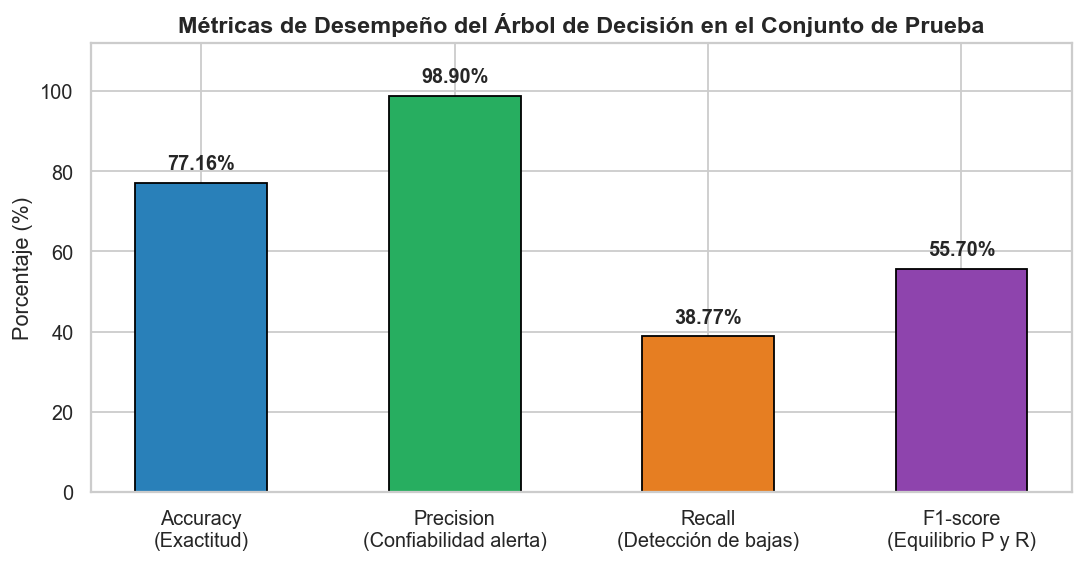

In [8]:
# Visualización comparativa de las 4 métricas de clasificación en el conjunto de prueba
fig, ax = plt.subplots(figsize=(8.5, 4.5))
nombres_m = ["Accuracy\n(Exactitud)", "Precision\n(Confiabilidad alerta)", "Recall\n(Detección de bajas)", "F1-score\n(Equilibrio P y R)"]
valores_m = [accuracy_val * 100, precision_val * 100, recall_val * 100, f1_val * 100]
colores_m = ["#2980b9", "#27ae60", "#e67e22", "#8e44ad"]

barras_m = ax.bar(nombres_m, valores_m, color=colores_m, edgecolor="black", width=0.52)
ax.set_title("Métricas de Desempeño del Árbol de Decisión en el Conjunto de Prueba")
ax.set_ylabel("Porcentaje (%)")
ax.set_ylim(0, 112)

for b in barras_m:
    h = b.get_height()
    ax.annotate(
        f"{h:.2f}%",
        xy=(b.get_x() + b.get_width() / 2, h),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center", va="bottom", fontweight="bold", fontsize=11
    )

plt.tight_layout()
plt.show()

### Interpretación individual de cada métrica sobre el comportamiento del modelo:

1. **`Accuracy = 0.7716` (77,16%):**
   * *¿Qué informa?* Indica la proporción global de aciertos del modelo sobre el total de reservas evaluadas (`5.787` aciertos entre `TP` y `TN` sobre `7.500` casos de prueba).
   * *Lectura crítica:* Supera ampliamente la tasa base de la clase mayoritaria (si un modelo trivial predijera siempre "No Cancela", acertaría el 62,96%). Sin embargo, mirar únicamente el 77,16% de `Accuracy` resulta insuficiente porque oculta una fuerte asimetría entre la capacidad para acertar casos negativos y la capacidad para detectar todas las cancelaciones reales.
2. **`Precision = 0.9890` (98,90%):**
   * *¿Qué informa?* Responde a la pregunta: *cuando el modelo predice que una reserva se va a cancelar, ¿qué proporción de esas alertas es realmente una cancelación?* De las `1.089` reservas que el modelo marcó como cancelación (`1.077 TP + 12 FP`), **acertó en el 98,90% de los casos**.
   * *Lectura crítica:* El modelo es **extremadamente preciso y conservador** al emitir una alerta positiva: prácticamente no genera falsas alarmas (`FP = 12`), porque solo clasifica como `1` aquellas reservas con señales fortísimas de baja (como depósito `Non Refund` o clientes con antecedentes de cancelación previa y alta anticipación).
3. **`Recall = 0.3877` (38,77%):**
   * *¿Qué informa?* Responde a la pregunta: *de todas las reservas que realmente se cancelaron en el conjunto de prueba (`2.778`), ¿qué proporción logró capturar el modelo?* El clasificador detectó `1.077` de las `2.778` cancelaciones reales (**38,77%**), dejando sin detectar el **61,23% restante (`1.701 FN`)**.
   * *Lectura crítica:* Es el punto más débil del árbol de profundidad 3: la mayoría de las cancelaciones que ocurren en reservas comunes (modalidad `No Deposit` y sin antecedentes previos) quedan en nodos hoja donde la probabilidad de cancelación ronda el 36,9%, lo cual está por debajo del umbral estándar del 50% y hace que el árbol las clasifique como `0`.
4. **`F1-score = 0.5570` (55,70%):**
   * *¿Qué informa?* Es la media armónica entre `Precision` y `Recall`. A diferencia de un promedio simple (que daría 68,8%), el `F1-score` penaliza el desequilibrio cuando una de las dos métricas es baja.
   * *Lectura crítica:* El valor de **55,70%** sintetiza con realismo que, si bien el modelo posee una confiabilidad casi perfecta cuando alerta (`Precision = 98,90%`), su sensibilidad moderada-baja (`Recall = 38,77%`) limita su cobertura global sobre la clase positiva.

---

## 6. Interpretación de los Errores en el Contexto de las Reservas Hoteleras

### 6.1. ¿Qué significa cada tipo de error en el negocio hotelero?

| Tipo de Error | Cantidad en Test | Significado en el Problema | Consecuencias Operativas y Comerciales para el Hotel |
|---|---:|---|---|
| **Falso Positivo (`FP`)** | **12 casos** (0,16% del test) | El modelo **predice que la reserva se cancelará (`1`)**, pero el huésped **NO cancela y se presenta al *check-in* (`0`)**. | • Si el hotel utiliza la predicción para hacer **sobreventa (*overbooking*)** y revende esa habitación, se encontrará con dos clientes para una misma plaza (*walk-in conflict*), debiendo reubicar al huésped en otro hotel a costo propio, pagar compensaciones y sufrir **daño reputacional**.<br/>• Si la usa para exigir prepago agresivo o cancelar preventivamente la reserva, puede molestar y perder a un cliente fiel. |
| **Falso Negativo (`FN`)** | **1.701 casos** (22,68% del test) | El modelo **predice que la reserva se mantendrá firme (`0`)**, pero el cliente **finalmente CANCELA la estadía (`1`)**. | • El hotel confía en esa ocupación proyectada y no toma recaudos comerciales.<br/>• Cuando la cancelación ocurre cerca de la fecha de arribo (o como *No-Show*), la **habitación queda vacía** (capacidad perecedera no vendida), generando **pérdida directa de ingresos por habitación (`ADR` + consumos)** y desaprovechamiento de campañas de reconfirmación temprana. |

### 6.2. Análisis complementario en SQL: ¿Dónde se concentran los errores del modelo?
Siguiendo el enfoque de la Unidad N° 6, consultamos mediante **SQL** cómo se distribuyen los Falsos Negativos (`FN`) y Falsos Positivos (`FP`) según el tipo de hotel y el segmento de mercado:

In [9]:
# Consulta SQL: Desglose de aciertos y errores (FP y FN) según Tipo de Hotel y Segmento de Mercado
errores_por_segmento = con.sql("""
SELECT
    hotel,
    market_segment,
    COUNT(*) AS casos_test,
    SUM(CASE WHEN is_canceled = 1 AND predicted_canceled = 1 THEN 1 ELSE 0 END) AS TP,
    SUM(CASE WHEN is_canceled = 0 AND predicted_canceled = 0 THEN 1 ELSE 0 END) AS TN,
    SUM(CASE WHEN is_canceled = 0 AND predicted_canceled = 1 THEN 1 ELSE 0 END) AS FP_falsa_alarma,
    SUM(CASE WHEN is_canceled = 1 AND predicted_canceled = 0 THEN 1 ELSE 0 END) AS FN_no_detectada,
    ROUND(AVG(CASE WHEN is_canceled <> predicted_canceled THEN 1.0 ELSE 0.0 END) * 100, 2) AS tasa_error_pct
FROM evaluacion_modelo
GROUP BY hotel, market_segment
HAVING COUNT(*) >= 50
ORDER BY FN_no_detectada DESC
""").df()

errores_por_segmento

,hotel,market_segment,casos_test,TP,TN,FP_falsa_alarma,FN_no_detectada,tasa_error_pct
0,City Hotel,Online TA,2416,28.0,1529.0,0.0,859.0,35.55
1,Resort Hotel,Online TA,1117,10.0,733.0,1.0,373.0,33.48
2,City Hotel,Offline TA/TO,1040,353.0,567.0,1.0,119.0,11.54
3,City Hotel,Groups,867,520.0,279.0,0.0,68.0,7.84
4,City Hotel,Direct,401,7.0,327.0,0.0,67.0,16.71
5,Resort Hotel,Groups,382,118.0,203.0,2.0,59.0,15.97
6,Resort Hotel,Offline TA/TO,451,17.0,382.0,0.0,52.0,11.53
7,Resort Hotel,Direct,425,2.0,370.0,3.0,50.0,12.47
8,Resort Hotel,Corporate,162,4.0,129.0,2.0,27.0,17.90
9,City Hotel,Corporate,174,18.0,138.0,3.0,15.0,10.34


### 6.3. ¿Cuál de los dos errores es especialmente relevante para la gestión hotelera? (Justificación)

En el contexto de este problema y a la luz de los resultados obtenidos, **el error especialmente relevante a atender es el Falso Negativo (`FN = 1.701 casos`)**, por dos razones fundamentales:

1. **Magnitud empírica y pérdida silenciosa de ingresos:**
   * En nuestro modelo actual, los Falsos Positivos son prácticamente inexistentes (`12` casos en `7.500` reservas), mientras que los **Falsos Negativos ascienden a `1.701` reservas** (concentradas sobre todo en `Online TA` del `City Hotel` con `885 FN` y del `Resort Hotel` con `384 FN`).
   * Cada Falso Negativo representa una reserva que la gerencia cree asegurada pero que se caerá. Considerando la estadía mediana de 3 noches y una tarifa mediana de ~\$96,30 por noche en reservas canceladas, no anticipar esas `1.701` bajas equivale a dejar expuestos cerca de **\$490.000 en ingresos brutos potenciales** en la muestra de prueba sin aplicar ninguna acción preventiva.
2. **Viabilidad de acciones preventivas de bajo costo ante la detección:**
   * Si el objetivo de la gestión hotelera es **implementar medidas preventivas no invasivas** (como enviar recordatorios automáticos de confirmación por WhatsApp/email 15 días antes, ofrecer un pequeño beneficio por confirmar la estadía o solicitar una tarjeta en garantía), el costo de un Falso Positivo es mínimo (un mensaje enviado a un cliente que igual iba a viajar), mientras que **el costo de un Falso Negativo es altísimo** (perder la venta de la habitación porque nadie gestionó el riesgo a tiempo).
   * *Matiz estratégico:* Únicamente si el hotel pretendiera utilizar el modelo para **revender automáticamente la habitación (*overbooking* duro)**, el **Falso Positivo (`FP`)** pasaría a ser el error más peligroso por el costo legal y reputacional de dejar a un huésped sin habitación. Precisamente en ese escenario específico de *overbooking*, la altísima `Precision` actual del modelo (**98,90%**, con solo `12 FP`) resulta una ventaja operativa notable.

---

## 7. Conclusión General: Utilidad, Respaldo Empírico y Limitaciones del Modelo

### 7.1. ¿Aporta el modelo información útil para anticipar cancelaciones?
**Sí, el modelo aporta información claramente útil como primer sistema de alerta temprana**, especialmente para identificar el núcleo duro de reservas con altísima propensión a cancelarse antes de que ocurra la fecha de *check-in*, superando en más de 14 puntos porcentuales la exactitud de una clasificación ingenua por clase mayoritaria.

### 7.2. ¿Qué aspectos de su desempeño respaldan esta conclusión?
1. **Sólida capacidad de generalización sin sobreajuste:** La exactitud en el conjunto de prueba (**`Accuracy = 77,16%`** sobre `7.500` casos no vistos) se mantiene en el mismo nivel que en el conjunto de entrenamiento (**`76,50%`** sobre `17.500` casos), probando que las reglas aprendidas son consistentes.
2. **Confiabilidad casi perfecta en sus alertas positivas (`Precision = 98,90%`):** De las `1.089` reservas que el modelo señala como futuras cancelaciones en el conjunto de prueba, `1.077` se cancelan realmente (`TP = 1.077` vs. apenas `FP = 12`). Esto permite a la gerencia actuar con altísima seguridad sobre el segmento alertado.
3. **Interpretabilidad transparente:** Al tratarse de un árbol de decisión de 3 niveles, la gerencia puede auditar exactamente por qué se activa cada predicción (`deposit_type`, `previous_cancellations`, `lead_time` y `total_of_special_requests`).

### 7.3. ¿Qué limitaciones deben considerarse antes de utilizar sus predicciones para tomar decisiones?
1. **Sensibilidad moderada-baja (`Recall = 38,77%`) y alto volumen de Falsos Negativos (`FN = 1.701`):** El modelo detecta menos de 4 de cada 10 cancelaciones reales. En particular, en reservas de agencias online (`Online TA`) sin depósito previo (`No Deposit`), el árbol asigna probabilidades cercanas a `0.37` (por debajo del umbral de `0.50`), dejando pasar muchas cancelaciones sin alertar. Antes de decidir, sería recomendable utilizar las **probabilidades estimadas** (por ejemplo, creando una franja de "riesgo moderado" entre `0.30` y `0.50`) en lugar de quedarse solo con la etiqueta binaria `0/1`.
2. **Dependencia de la variable `deposit_type` (*Non Refund*) y posible sesgo operativo:** Como advertimos en el EDA (Entrega 4), gran parte del poder discriminante inicial del árbol proviene de `deposit_type_Non Refund`. Debe verificarse con el área administrativa del hotel que esa etiqueta esté disponible genuinamente al momento de crear la reserva y no sea producto de una actualización contable posterior a la baja (*data leakage*).
3. **Omisión de factores contextuales y ausencia de causalidad:** El modelo no observa variables externas (clima, precios de la competencia, feriados o antelación exacta de aviso de la baja), y sus reglas reflejan **asociaciones históricas, no relaciones de causa-efecto**. Por ejemplo, que `Online TA` o un `lead_time` alto eleven la probabilidad de cancelación no significa que bloquear las ventas anticipadas vaya a aumentar la rentabilidad neta del hotel.

In [10]:
# Cierre limpio de la conexión a DuckDB
con.close()
print("🔒 Conexión a DuckDB cerrada correctamente. Evaluación de la Entrega 6 completada con éxito.")

🔒 Conexión a DuckDB cerrada correctamente. Evaluación de la Entrega 6 completada con éxito.
